# Phase 12.2 - Gym leverage RL (GBPUSD)

Entrenamiento Actor-Critic en `gymnasium` para aprender magnitud de apalancamiento con direccion anclada al modelo base (signo de `pred_action`).


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

ROOT = Path('.')
PHASE12 = ROOT / 'phases/phase12_leverage_rl'
RUN_SCRIPT = PHASE12 / 'run_phase12_2_gym_leverage.py'
OUT_DIR = PHASE12 / 'output_phase12_2_gym_leverage_GBPUSD'

OUT_SUMMARY = OUT_DIR / 'GBPUSD_phase12_2_summary.json'
OUT_COMPARE = OUT_DIR / 'GBPUSD_phase12_2_policy_comparison.csv'
OUT_TRIALS = OUT_DIR / 'GBPUSD_phase12_2_trials.csv'
OUT_PRED = OUT_DIR / 'GBPUSD_phase12_2_holdout_predictions.csv'


In [2]:
# Ejecutar desde terminal con conda (recomendado):
# source ~/miniconda3/etc/profile.d/conda.sh && conda activate torch-gpu-pip && python "${RUN_SCRIPT}"

print('Script:', RUN_SCRIPT)
print('Output dir:', OUT_DIR)
print('Summary exists:', OUT_SUMMARY.exists())


Script: ./phases/phase12_leverage_rl/run_phase12_2_gym_leverage.py
Output dir: ./phases/phase12_leverage_rl/output_phase12_2_gym_leverage_GBPUSD
Summary exists: True


In [3]:
summary = json.loads(OUT_SUMMARY.read_text())
compare_df = pd.read_csv(OUT_COMPARE)
trials_df = pd.read_csv(OUT_TRIALS).sort_values('val_score_q', ascending=False)

display(pd.DataFrame([summary['best_trial_row']]))
display(compare_df)
display(trials_df)


,trial,risk_penalty,lev_bonus,force_nonzero,val_score_q,val_avg_q,val_sharpe_q,val_avg_abs_lev_q,holdout_cum_q,holdout_cum_behavior_1x,holdout_cum_behavior_2x
0,t1_forced_light,0.00002,0.00002,True,5.779032,0.000526,5.136097,0.299415,0.754839,0.58665,1.1733


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades,avg_abs_lev,avg_abs_lev_on_trade
0,validation,behavior_1x,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502,0.361988,1.000000
1,validation,behavior_2x,0.337427,0.332445,0.000456,0.780049,0.010362,0.361988,3.423678,0.531502,0.723977,2.000000
2,validation,gym_q_leverage,0.337427,0.332445,0.000526,0.899875,0.007968,0.361988,5.136097,0.531502,0.299415,0.827141
3,holdout,behavior_1x,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840,0.360400,1.000000
4,holdout,behavior_2x,0.326196,0.324551,0.000326,1.173300,0.008076,0.360400,3.141828,0.547840,0.720801,2.000000
5,holdout,gym_q_leverage,0.326196,0.324551,0.000210,0.754839,0.005084,0.360400,3.211067,0.547840,0.366935,1.018133


,trial,risk_penalty,lev_bonus,force_nonzero,val_score_q,val_avg_q,val_sharpe_q,val_avg_abs_lev_q,holdout_cum_q,holdout_cum_behavior_1x,holdout_cum_behavior_2x
0,t1_forced_light,0.00002,0.00002,True,5.779032,0.000526,5.136097,0.299415,0.754839,0.58665,1.1733
1,t0_neutral,0.00002,0.00000,False,4.768589,0.000437,3.993024,0.423392,0.816972,0.58665,1.1733
2,t2_forced_stronger,0.00001,0.00005,True,2.875851,0.000252,3.567653,0.222222,0.428513,0.58665,1.1733


In [4]:
pred = pd.read_csv(OUT_PRED)
lev_counts = pred['lev_gym_q_leverage'].round(4).value_counts().sort_index()
display(lev_counts.to_frame('count'))

print('n_holdout:', len(pred))
print('mean_abs_lev:', pred['lev_gym_q_leverage'].abs().mean())
print('nonzero_rate:', (pred['lev_gym_q_leverage'] != 0).mean())
print('gt_1x_rate:', (pred['lev_gym_q_leverage'].abs() > 1.0).mean())


,count
lev_gym_q_leverage,
-2.0,272
-1.5,4
-1.0,34
-0.5,312
0.0,2300
0.5,413
1.0,145
1.5,8
2.0,108


n_holdout: 3596
mean_abs_lev: 0.36693548387096775
nonzero_rate: 0.3604004449388209
gt_1x_rate: 0.10901001112347053


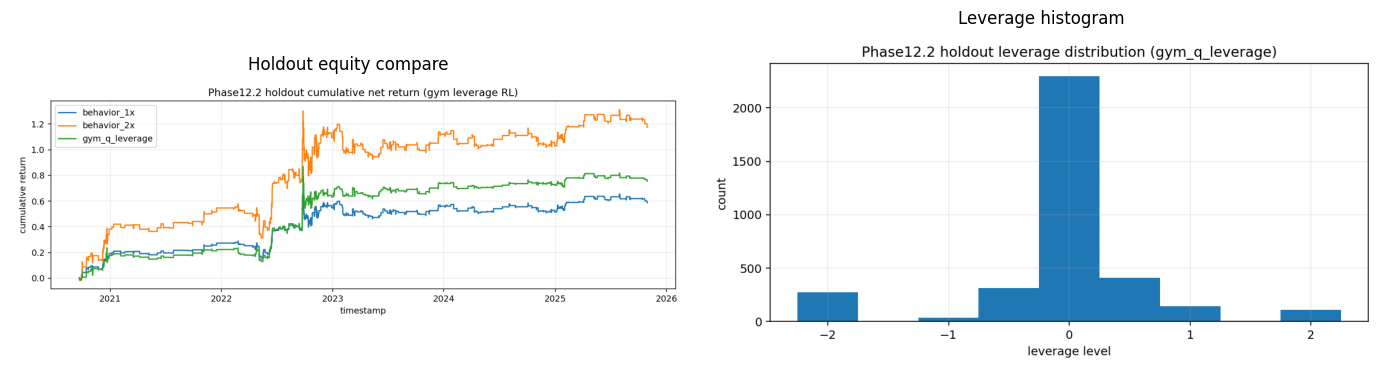

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(mpimg.imread(OUT_DIR / 'GBPUSD_phase12_2_holdout_equity_compare.png'))
axes[0].axis('off')
axes[0].set_title('Holdout equity compare')

axes[1].imshow(mpimg.imread(OUT_DIR / 'GBPUSD_phase12_2_holdout_leverage_hist.png'))
axes[1].axis('off')
axes[1].set_title('Leverage histogram')

plt.tight_layout()
